In [ ]:
import pandas as pd

raw_dataset = pd.read_csv("listings (1).csv.gz")
raw_dataset.head()

In [ ]:
#copiamos el conjunto para preservarlo
preprocessed_dataset = raw_dataset.copy()

#borramos columnas con todos sus valores nulos
preprocessed_dataset = preprocessed_dataset.drop('neighborhood_overview', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_since', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_time', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_response_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_acceptance_rate', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_thumbnail_url', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_total_listings_count', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_verifications', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('neighbourhood_group_cleansed', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('calendar_updated', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('instant_bookable', axis=1)
preprocessed_dataset = preprocessed_dataset.drop('listing_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_profile_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_name',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('scrape_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('picture_url',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('host_id',axis=1)
preprocessed_dataset = preprocessed_dataset.drop('license',axis=1)

preprocessed_dataset.info()

In [28]:
pd.set_option("display.max_rows", None)

# Hay alguno usuarios que desde que se registraron en la plataforma son host
#preprocessed_dataset[['hosts_time_as_host_years','hosts_time_as_host_months', 'hosts_time_as_user_years','hosts_time_as_user_months']]

users_history_only_host = preprocessed_dataset[
    (preprocessed_dataset['hosts_time_as_host_years'] == preprocessed_dataset['hosts_time_as_user_years']) &
     (preprocessed_dataset['hosts_time_as_host_months'] == preprocessed_dataset['hosts_time_as_user_months'])
]


print(f"{len(users_history_only_host)} de {len(preprocessed_dataset)} hosts tienen el mismo tiempo")

# Posible hipotesis:
# --- ¿Bi variada? ---
# De todas las cuentas que desde que se crearon funcionan como host, la gran mayoria son empresas multiviviendas

9513 de 29685 hosts tienen el mismo tiempo


### Analisis de hipotesis univaridad

Los alquileres no bajan de $x en la ciudad de buenos aires en AirBnB

*reformulacion* : El 95% de los alquileres en la ciudad de Buenos Aires no bajan de $x por noche

In [ ]:
# Analisis hipotesis: 


### Analisis de hipotesis: bivariada

Cuántas de las propiedades de los 5 barrios con más publicaciones pertenecen a agencias multipropiedad y cuantas a un host que cuenta con una única propiedad

*reformulacion* : Dentro de los 5 barrios con mas publicaciones, aproximadamente 2 de cada 3 propiedades pertecen a host con mas de una propiedad

Reviews atadas a la localización dependen del barrio

In [ ]:
#aa

### Analisis de hipotesis: _Multivariada_

Un host con foto de perfil da más confiabilidad (mejores reviews, menos disponibilidad)

In [10]:
precio = preprocessed_dataset["price_quote_price_per_night"].dropna()
print(len(precio))   # propiedades con precio

27893


/tmp/ipykernel_756739/4143229897.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1].boxplot(precio[precio < precio.quantile(.99)], vert=False)


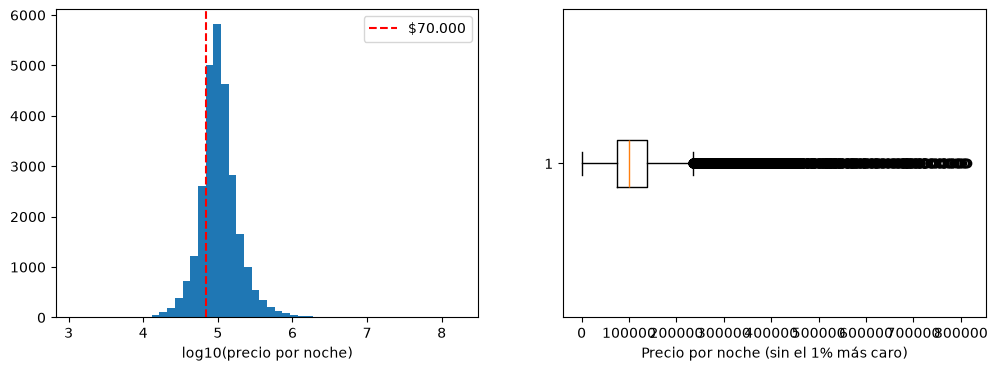

In [11]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(np.log10(precio), bins=50)
ax[0].axvline(np.log10(70000), color="red", linestyle="--", label="$70.000")
ax[0].set_xlabel("log10(precio por noche)")
ax[0].legend()
ax[1].boxplot(precio[precio < precio.quantile(.99)], vert=False)
ax[1].set_xlabel("Precio por noche (sin el 1% más caro)")
plt.show()

/tmp/ipykernel_756739/3365518133.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(precio, vert=False)


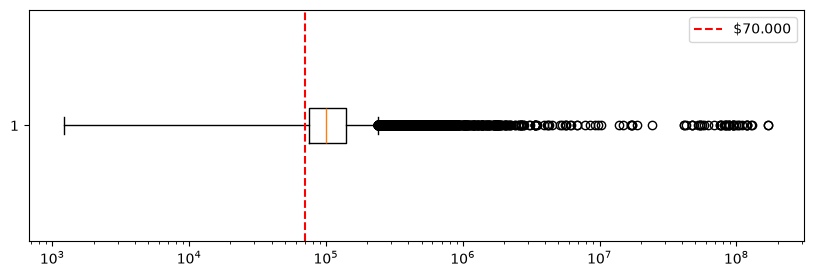

In [13]:
fig, ax = plt.subplots(figsize=(10, 3))
ax.boxplot(precio, vert=False)
ax.set_xscale("log")
ax.axvline(70000, color="red", linestyle="--", label="$70.000")
ax.legend()
plt.show()

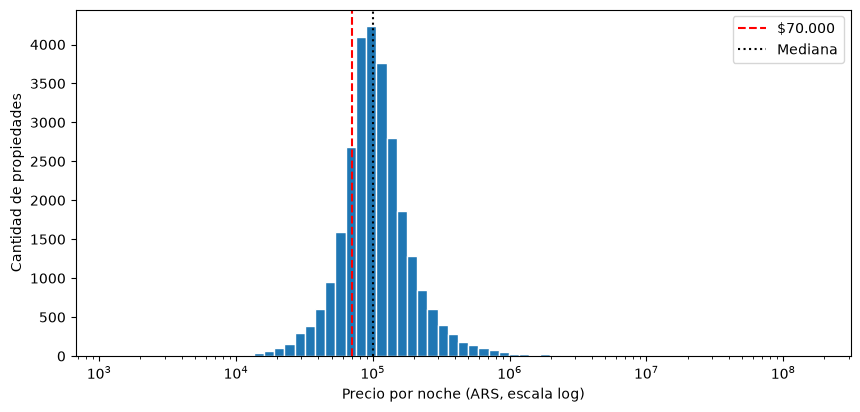

In [12]:

bins = np.logspace(np.log10(precio.min()), np.log10(precio.max()), 70)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(precio, bins=bins, edgecolor="white")
ax.set_xscale("log")
ax.axvline(70000, color="red", linestyle="--", label="$70.000")
ax.axvline(precio.median(), color="black", linestyle=":", label="Mediana")
ax.set_xlabel("Precio por noche (ARS, escala log)")
ax.set_ylabel("Cantidad de propiedades")
ax.legend()
plt.show()